In [3]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

TAREA 1: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaría en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y milímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc.

### Imagen ideal

Diametro(mm): 25.75 mm, Diametro(px): 208.00 px, valor: 2.00 EUR, error: 0.000
Diametro(mm): 22.53 mm, Diametro(px): 182.00 px, valor: 0.20 EUR, error: 0.281
Diametro(mm): 22.28 mm, Diametro(px): 180.00 px, valor: 0.20 EUR, error: 0.034
Diametro(mm): 21.54 mm, Diametro(px): 174.00 px, valor: 0.05 EUR, error: 0.291
Diametro(mm): 20.06 mm, Diametro(px): 162.00 px, valor: 0.10 EUR, error: 0.305
Diametro(mm): 19.06 mm, Diametro(px): 154.00 px, valor: 0.02 EUR, error: 0.315
Diametro(mm): 18.57 mm, Diametro(px): 150.00 px, valor: 0.02 EUR, error: 0.180
Diametro(mm): 16.34 mm, Diametro(px): 132.00 px, valor: 0.01 EUR, error: 0.091
Se han encontrado 8 monedas
Valor total de las monedas: 2.60 €


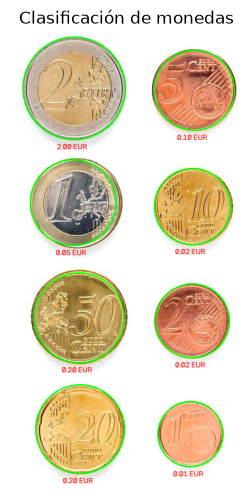

In [7]:
# Cargar imagen en RGB
img = cv2.imread('Monedas.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Conversión a gris
grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Suavizado de imagen eliminando altas frecuencias
grey_filter = cv2.medianBlur(grey, 7)

# Detección de círculos
circles = cv2.HoughCircles(
    grey_filter,  # imagen 
    cv2.HOUGH_GRADIENT,  # tipo de detección
    1,
    100,  # distancia mínima entre círculos
    param1=100, # valor del gradiente
    param2=50, # umbral acumulador
    minRadius=50,  # radio mínimo
    maxRadius=150,  # radio máximo
)

circles = np.round(circles[0]).astype(int)

# Diccionario de monedas euro con su diametro en mm
coins = {
    0.01: 16.25,
    0.02: 18.75,
    0.05: 21.25,
    0.10: 19.75,
    0.20: 22.25,
    0.50: 24.25,
    1.00: 23.25,
    2.00: 25.75
}

values = np.array(list(coins.keys()))
diameters = np.array(list(coins.values()))

# Calibracion de mm/px en base a la moneda de 2€ (la de mayor diámetro)
r_max = max(r for x, y, r in circles)
ratio = coins[2.00] / (2 * r_max)

# Clasificación de monedas encotradas
img_result = img_rgb.copy()
total = 0
total_value = 0.0

for x, y, r in circles:
    # Convertir diámetro de px a mm
    px_diameter = 2 * r
    mm_diameter = px_diameter * ratio

    # Modena cuyo valor del diámetro real esta más próximo
    diffs = np.abs(diameters - mm_diameter)
    index = np.argmin(diffs)

    # Error de la diferencia
    error = diffs[index]

    # Se recupera el valor en euros y suma al total
    value = values[index]
    total_value += value

    # Se añade una a las monedas encontradas
    total += 1

    # Se señala la moneda en la imagen
    cv2.circle(img_result, (x, y), r, (0, 255, 0), 2)

    # Etiqueta de la moneda
    label = f"{value:.2f} EUR"
    cv2.putText(img_result, label, (x - 35, y + r + 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1, cv2.LINE_AA)

    # Se imprime la información de la moneda por pantalla
    print(f"Diametro(mm): {mm_diameter:.2f} mm, Diametro(px): {px_diameter:.2f} px, valor: {value:.2f} EUR, error: {error:.3f}")

# Se imprime el número de monedas y el valor total
print(f"Se han encontrado {total} monedas")
print(f"Valor total de las monedas: {total_value:.2f} €")


# Visualiza la imagen
plt.figure(figsize=(6, 6))
plt.imshow(img_result)
plt.title("Clasificación de monedas")
plt.axis("off")
plt.show()


Diametro(mm): 15.84 mm, Diametro(px): 127.63 px, valor: 0.01 EUR, error: 0.409
Diametro(mm): 18.74 mm, Diametro(px): 150.96 px, valor: 0.02 EUR, error: 0.012
Diametro(mm): 19.49 mm, Diametro(px): 157.05 px, valor: 0.10 EUR, error: 0.256
Diametro(mm): 20.69 mm, Diametro(px): 166.70 px, valor: 0.05 EUR, error: 0.558
Diametro(mm): 21.98 mm, Diametro(px): 177.05 px, valor: 0.20 EUR, error: 0.274
Diametro(mm): 22.75 mm, Diametro(px): 183.30 px, valor: 1.00 EUR, error: 0.498
Diametro(mm): 23.94 mm, Diametro(px): 192.85 px, valor: 0.50 EUR, error: 0.313
Diametro(mm): 25.75 mm, Diametro(px): 207.45 px, valor: 2.00 EUR, error: 0.000
Se han encontrado 8 monedas
Valor total de las monedas: 3.88 €


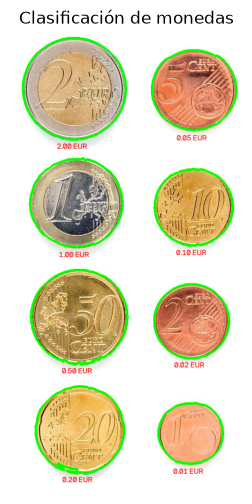

In [8]:
# Cargar imagen en RGB
img = cv2.imread('Monedas.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Conversión a gris
grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Suavizado de imagen eliminando altas frecuencias
grey_filter = cv2.medianBlur(grey, 7)

# Umbralizado con método de Otsu 
_, img_umb = cv2.threshold(grey_filter, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Detección de contornos externos
contours, _ = cv2.findContours(
    img_umb,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Filtrado de contornos pequeños, que posiblemente no son monendas
min_area = 100
contours = [c for c in contours if cv2.contourArea(c) >= min_area]

# Ordenar contornos por área
contours = sorted(contours, key=cv2.contourArea)

# Diccionario de monedas euro con su diametro en mm
coins = {
    0.01: 16.25,
    0.02: 18.75,
    0.05: 21.25,
    0.10: 19.75,
    0.20: 22.25,
    0.50: 24.25,
    1.00: 23.25,
    2.00: 25.75
}

values = np.array(list(coins.keys()))
diameters = np.array(list(coins.values()))

# Cálculo del diametro de las monedas encontradas
areas = np.array([cv2.contourArea(c) for c in contours])
diameters_px = 2 * np.sqrt(areas / np.pi)

# Calibracion de mm/px en base a la moneda de 2€ (la de mayor diámetro)
ratio = coins[2.00] / max(diameters_px)

#Dibuja sobre la imagen de entrada sólo contornos externos
img_result = img_rgb.copy()
cv2.drawContours(img_result, contours, -1, (0,255,0), 3)

# Clasificación de monedas encotradas
total = 0
total_value = 0.0

for c, area, px_diameter in zip(contours, areas, diameters_px):
    # Convertir diámetro de px a mm
    mm_diameter = px_diameter * ratio

    # Modena cuyo valor del diámetro real esta más próximo
    diffs = np.abs(diameters - mm_diameter)
    index = np.argmin(diffs)

    # Error de la diferencia
    error = diffs[index]

    # Se recupera el valor en euros y suma al total
    value = values[index]
    total_value += value

    # Se añade una a las monedas encontradas
    total += 1

    # Se encuentra el centro aprox. de la moneda
    M = cv2.moments(c)

    if M["m00"] != 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])

    # Etiqueta de la moneda
    label = f"{value:.2f} EUR"
    cv2.putText(img_result, label, (int(cx - 35), int(cy + (px_diameter/2) + 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1, cv2.LINE_AA)

    # Se imprime la información de la moneda por pantalla
    print(f"Diametro(mm): {mm_diameter:.2f} mm, Diametro(px): {px_diameter:.2f} px, valor: {value:.2f} EUR, error: {error:.3f}")

# Se imprime el número de monedas y el valor total
print(f"Se han encontrado {total} monedas")
print(f"Valor total de las monedas: {total_value:.2f} €")

# Visualiza la imagen
plt.figure(figsize=(6, 6))
plt.imshow(img_result)
plt.title("Clasificación de monedas")
plt.axis("off")
plt.show()


### Cámara

In [ ]:
#Cámara

TAREA 2: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo